```markdown
# Project Title: Time-Series Signal Anomaly Detection

This project focuses on preprocessing, analyzing, and building machine learning models (Logistic Regression, Random Forest, and Decision Trees) to detect anomalies in channel-based sampling segments.
```

Importing the libraries

```markdown
## Step 1: Libraries and Environment Setup
```

In [125]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


```markdown
## Step 2: Data Acquisition and Loading
```

In [126]:
data  =pd.read_csv('/content/dataset.csv')
df = pd.DataFrame(data)
df

,segment,anomaly,train,channel,sampling,duration,len,mean,var,std,...,smooth10_n_peaks,smooth20_n_peaks,diff_peaks,diff2_peaks,diff_var,diff2_var,gaps_squared,len_weighted,var_div_duration,var_div_len
0,1,1,1,CADC0872,1,279,280,8.533143e-07,3.494283e-10,0.000019,...,3,2,4,6,1.271176e-10,2.960666e-10,279,280,1.252431e-12,1.247958e-12
1,2,1,1,CADC0872,1,476,477,-3.639396e-06,6.476485e-10,0.000025,...,1,1,5,8,1.489383e-12,3.004752e-12,476,477,1.360606e-12,1.357754e-12
2,3,1,1,CADC0872,1,594,595,1.170788e-05,5.592877e-10,0.000024,...,2,2,2,3,4.112280e-12,1.029918e-11,594,595,9.415618e-13,9.399794e-13
3,4,1,1,CADC0872,1,271,272,8.486808e-07,5.466024e-10,0.000023,...,2,2,3,6,2.475760e-11,6.240985e-11,271,272,2.016983e-12,2.009568e-12
4,5,0,0,CADC0872,1,256,257,1.058485e-05,5.279023e-10,0.000023,...,1,1,78,87,5.547101e-13,7.035422e-13,256,257,2.062118e-12,2.054094e-12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2118,2119,0,0,CADC0872,5,155,32,-2.638445e-05,1.365061e-10,0.000012,...,1,1,4,7,5.643170e-12,9.612178e-13,775,160,8.806842e-13,4.265814e-12
2119,2120,0,1,CADC0872,5,165,34,-2.318618e-05,1.988522e-10,0.000014,...,1,1,4,9,7.349826e-12,1.162888e-12,825,170,1.205165e-12,5.848595e-12
2120,2121,0,1,CADC0872,5,140,29,-3.137510e-05,1.146533e-10,0.000011,...,1,1,3,7,5.763149e-12,9.522562e-13,700,145,8.189522e-13,3.953562e-12
2121,2122,0,1,CADC0872,5,200,41,-5.376693e-06,7.755461e-10,0.000028,...,1,1,2,12,1.837184e-11,1.123874e-12,1000,205,3.877731e-12,1.891576e-11


```markdown
## Step 3: Exploratory Data Analysis (EDA)
We inspect data dimensions, missing values, duplicates, statistical properties, class balance, and correlation structure.
```

In [127]:
df.shape

(2123, 23)

In [128]:
df.head()

,segment,anomaly,train,channel,sampling,duration,len,mean,var,std,...,smooth10_n_peaks,smooth20_n_peaks,diff_peaks,diff2_peaks,diff_var,diff2_var,gaps_squared,len_weighted,var_div_duration,var_div_len
0,1,1,1,CADC0872,1,279,280,8.533143e-07,3.494283e-10,0.000019,...,3,2,4,6,1.271176e-10,2.960666e-10,279,280,1.252431e-12,1.247958e-12
1,2,1,1,CADC0872,1,476,477,-3.639396e-06,6.476485e-10,0.000025,...,1,1,5,8,1.489383e-12,3.004752e-12,476,477,1.360606e-12,1.357754e-12
2,3,1,1,CADC0872,1,594,595,1.170788e-05,5.592877e-10,0.000024,...,2,2,2,3,4.112280e-12,1.029918e-11,594,595,9.415618e-13,9.399794e-13
3,4,1,1,CADC0872,1,271,272,8.486808e-07,5.466024e-10,0.000023,...,2,2,3,6,2.475760e-11,6.240985e-11,271,272,2.016983e-12,2.009568e-12
4,5,0,0,CADC0872,1,256,257,1.058485e-05,5.279023e-10,0.000023,...,1,1,78,87,5.547101e-13,7.035422e-13,256,257,2.062118e-12,2.054094e-12


In [129]:
df.tail()

,segment,anomaly,train,channel,sampling,duration,len,mean,var,std,...,smooth10_n_peaks,smooth20_n_peaks,diff_peaks,diff2_peaks,diff_var,diff2_var,gaps_squared,len_weighted,var_div_duration,var_div_len
2118,2119,0,0,CADC0872,5,155,32,-0.000026,1.365061e-10,0.000012,...,1,1,4,7,5.643170e-12,9.612178e-13,775,160,8.806842e-13,4.265814e-12
2119,2120,0,1,CADC0872,5,165,34,-0.000023,1.988522e-10,0.000014,...,1,1,4,9,7.349826e-12,1.162888e-12,825,170,1.205165e-12,5.848595e-12
2120,2121,0,1,CADC0872,5,140,29,-0.000031,1.146533e-10,0.000011,...,1,1,3,7,5.763149e-12,9.522562e-13,700,145,8.189522e-13,3.953562e-12
2121,2122,0,1,CADC0872,5,200,41,-0.000005,7.755461e-10,0.000028,...,1,1,2,12,1.837184e-11,1.123874e-12,1000,205,3.877731e-12,1.891576e-11
2122,2123,1,1,CADC0872,5,145,30,-0.000014,2.918613e-10,0.000017,...,1,2,1,1,2.448748e-10,7.221565e-10,725,150,2.012836e-12,9.728709e-12


In [130]:
df.dtypes

,0
segment,int64
anomaly,int64
train,int64
channel,object
sampling,int64
duration,int64
len,int64
mean,float64
var,float64
std,float64


In [131]:
df.isna().sum()

,0
segment,0
anomaly,0
train,0
channel,0
sampling,0
duration,0
len,0
mean,0
var,0
std,0


In [132]:
df.duplicated().sum()

np.int64(0)

In [133]:
df.describe()

,segment,anomaly,train,sampling,duration,len,mean,var,std,kurtosis,...,smooth10_n_peaks,smooth20_n_peaks,diff_peaks,diff2_peaks,diff_var,diff2_var,gaps_squared,len_weighted,var_div_duration,var_div_len
count,2123.000000,2123.000000,2123.000000,2123.000000,2123.000000,2123.000000,2.123000e+03,2.123000e+03,2123.000000,2123.000000,...,2123.000000,2123.000000,2123.000000,2123.000000,2.123000e+03,2.123000e+03,2123.000000,2123.000000,2.123000e+03,2.123000e+03
mean,1062.000000,0.204428,0.750824,3.505888,265.613754,142.954781,1.109677e-01,3.065868e-02,0.096226,-1.085494,...,1.110221,1.181818,18.110692,25.286387,9.166359e-04,1.045846e-03,999.228450,267.925106,1.176063e-04,4.361427e-04
std,613.001631,0.403378,0.432638,1.935418,167.158550,152.329786,1.963165e-01,5.491161e-02,0.146319,1.000566,...,0.399227,0.425295,28.991979,32.737797,4.196259e-03,1.127395e-02,1565.349081,166.245528,2.119295e-04,8.845658e-04
min,1.000000,0.000000,0.000000,1.000000,35.000000,8.000000,-3.833030e-05,1.422763e-11,0.000004,-1.858813,...,0.000000,0.000000,0.000000,0.000000,1.962330e-13,3.875356e-13,104.000000,40.000000,2.817267e-14,4.404840e-14
25%,531.500000,0.000000,1.000000,1.000000,175.000000,40.000000,-7.239804e-07,2.960552e-10,0.000017,-1.449123,...,1.000000,1.000000,1.000000,4.000000,3.163852e-12,1.233331e-12,295.000000,175.000000,1.309137e-12,2.809916e-12
50%,1062.000000,0.000000,1.000000,5.000000,225.000000,70.000000,4.515496e-06,6.032890e-10,0.000025,-1.302729,...,1.000000,1.000000,5.000000,14.000000,3.640618e-11,1.095135e-11,500.000000,230.000000,3.786876e-12,1.563517e-11
75%,1592.500000,0.000000,1.000000,5.000000,330.000000,201.000000,2.051710e-01,3.738843e-02,0.193361,-0.996211,...,1.000000,1.000000,21.000000,32.000000,2.982598e-04,1.402282e-04,1200.000000,330.000000,1.886576e-04,4.718514e-04
max,2123.000000,1.000000,1.000000,5.000000,1335.000000,1040.000000,1.118632e+00,2.724801e-01,0.521996,31.201842,...,5.000000,4.000000,240.000000,256.000000,9.987869e-02,3.033986e-01,20750.000000,1340.000000,1.686516e-03,8.031028e-03


In [134]:
df['anomaly'].value_counts()

,count
anomaly,
0,1689
1,434


In [135]:
df['train'].value_counts()

,count
train,
1,1594
0,529


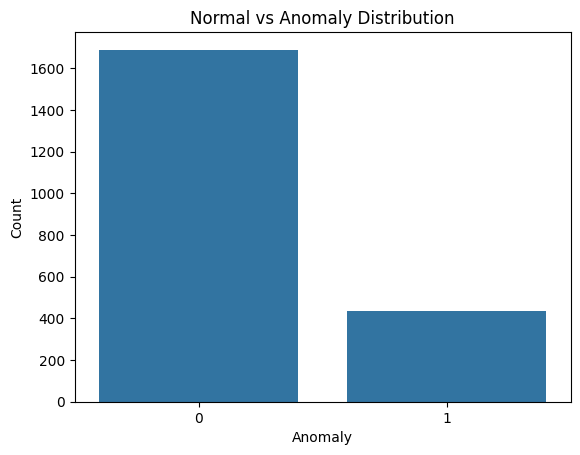

In [136]:
sns.countplot(x='anomaly',data=df)
plt.title('Normal vs Anomaly Distribution')
plt.xlabel('Anomaly')
plt.ylabel('Count')
plt.show()

In [137]:
df.corr(numeric_only=True)

,segment,anomaly,train,sampling,duration,len,mean,var,std,kurtosis,...,smooth10_n_peaks,smooth20_n_peaks,diff_peaks,diff2_peaks,diff_var,diff2_var,gaps_squared,len_weighted,var_div_duration,var_div_len
segment,1.000000,-0.133887,-0.009139,0.594096,-0.186441,-0.441953,-0.095082,-0.072263,-0.036008,0.048778,...,-0.175961,0.166357,-0.397870,-0.389892,0.063709,0.058242,0.136457,-0.184845,-0.036545,-0.012237
anomaly,-0.133887,1.000000,-0.013118,-0.267742,0.172199,0.293134,-0.161937,-0.185838,-0.173805,0.233905,...,0.527219,0.132104,-0.155948,-0.162844,0.108702,0.153694,0.111426,0.156882,-0.163552,-0.127807
train,-0.009139,-0.013118,1.000000,0.005411,-0.004316,-0.019249,0.005138,-0.008735,-0.002043,-0.008455,...,-0.040088,-0.061003,0.012081,0.015388,-0.002131,0.000042,0.017206,-0.005731,-0.009699,-0.007363
sampling,0.594096,-0.267742,0.005411,1.000000,-0.149977,-0.791557,0.174819,0.080157,0.093727,-0.095661,...,-0.250290,0.057668,-0.559012,-0.566322,0.161295,0.068812,0.345952,-0.144708,0.083846,0.298552
duration,-0.186441,0.172199,-0.004316,-0.149977,1.000000,0.579992,0.027387,0.166692,0.148886,0.094981,...,0.273536,-0.151097,0.338763,0.399275,-0.096862,-0.059614,0.421489,0.998048,-0.016356,-0.011377
len,-0.441953,0.293134,-0.019249,-0.791557,0.579992,1.000000,-0.127975,-0.027096,-0.034696,0.126388,...,0.380322,0.029282,0.595271,0.640647,-0.144525,-0.065919,-0.154553,0.577777,-0.096396,-0.235295
mean,-0.095082,-0.161937,0.005138,0.174819,0.027387,-0.127975,1.000000,0.660945,0.737551,0.001821,...,-0.137341,-0.233126,-0.175325,-0.145729,0.319710,0.131407,0.046588,0.032451,0.700724,0.661473
var,-0.072263,-0.185838,-0.008735,0.080157,0.166692,-0.027096,0.660945,1.000000,0.966811,0.052461,...,-0.139595,-0.233402,-0.150496,-0.103837,0.253804,0.087045,0.083289,0.171687,0.904349,0.788910
std,-0.036008,-0.173805,-0.002043,0.093727,0.148886,-0.034696,0.737551,0.966811,1.000000,0.070435,...,-0.152962,-0.269941,-0.173050,-0.124226,0.283795,0.111032,0.076276,0.153972,0.895407,0.782000
kurtosis,0.048778,0.233905,-0.008455,-0.095661,0.094981,0.126388,0.001821,0.052461,0.070435,1.000000,...,0.197549,-0.023397,-0.054897,-0.054359,0.115051,0.099874,0.073814,0.088471,0.057445,0.051430


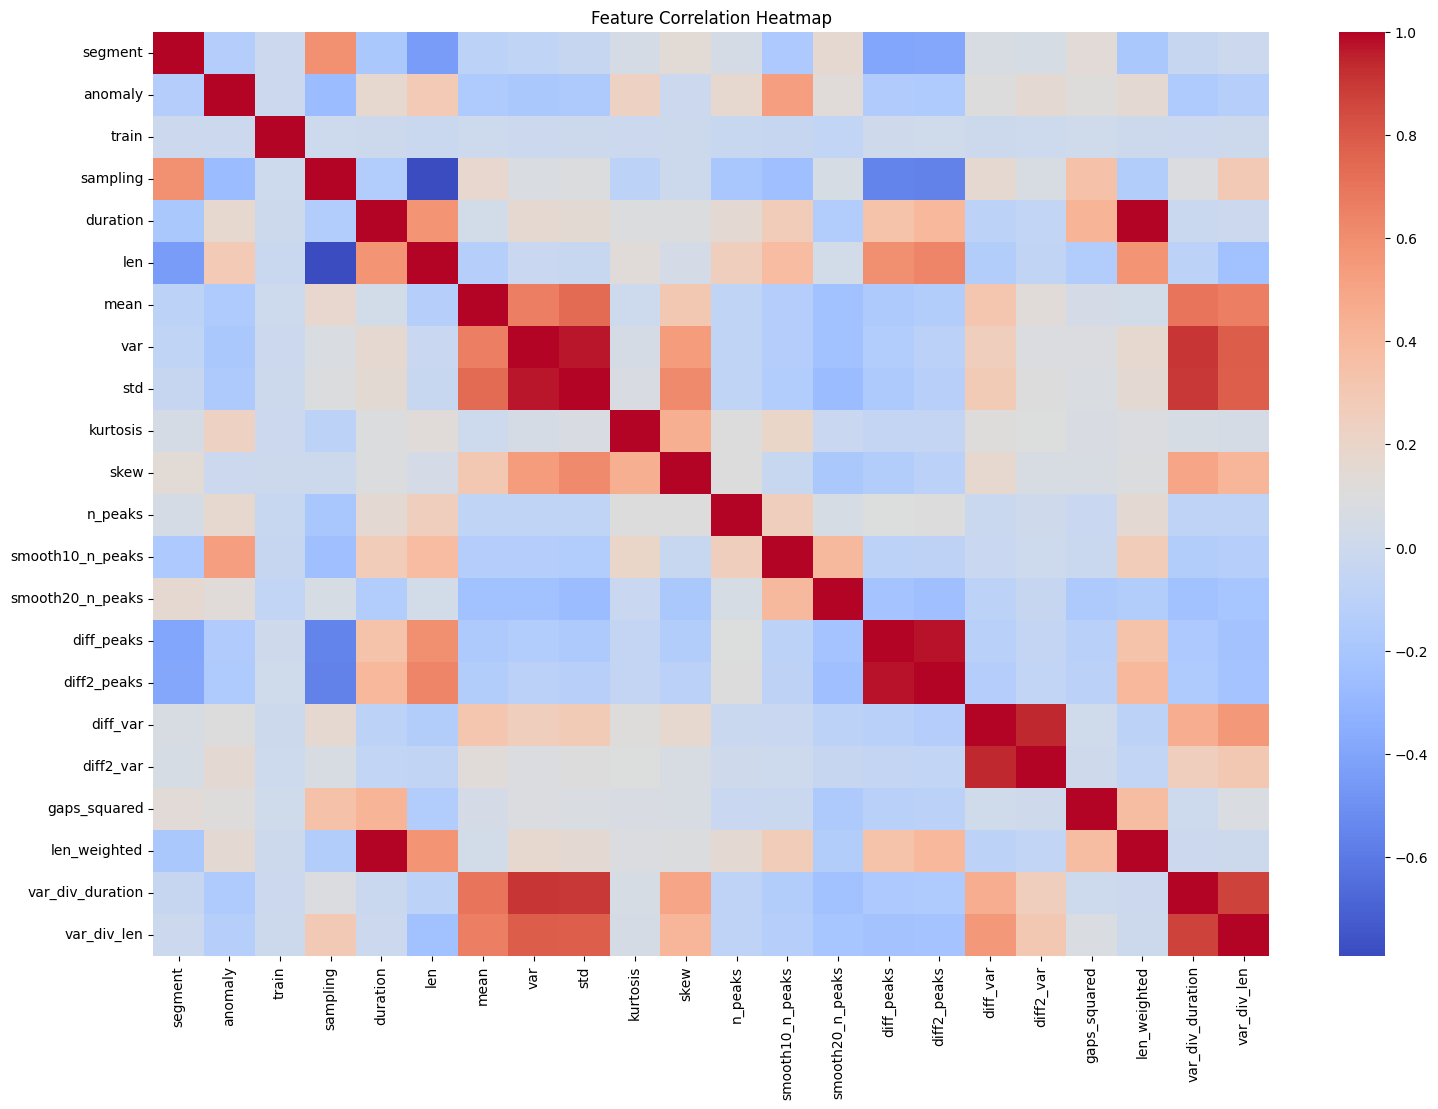

In [138]:
plt.figure(figsize=(18,12))

sns.heatmap(df.corr(numeric_only=True),cmap='coolwarm',annot=False)



plt.title('Feature Correlation Heatmap')
plt.show()

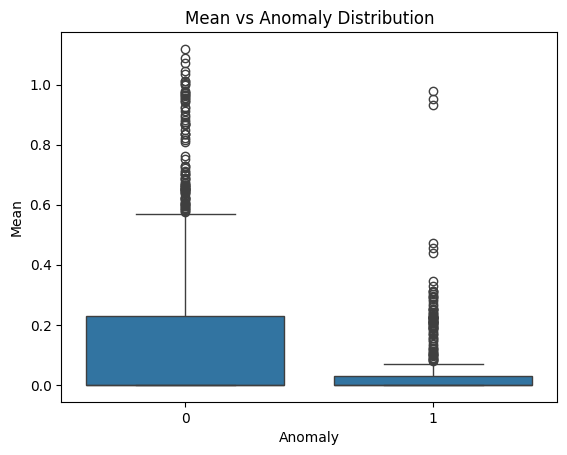

In [139]:
sns.boxplot(data=df,x='anomaly',y='mean')
plt.title('Mean vs Anomaly Distribution')
plt.xlabel('Anomaly')
plt.ylabel('Mean')
plt.show()

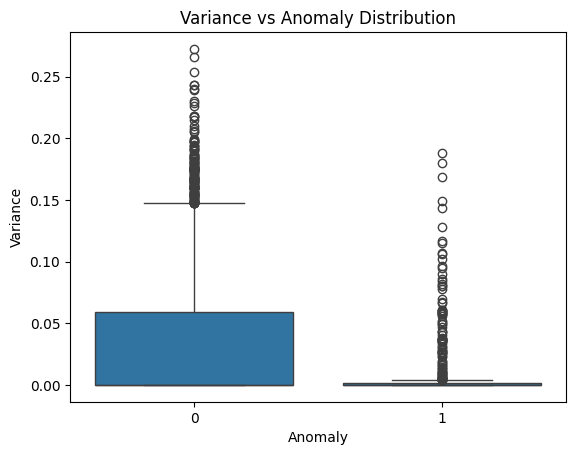

In [140]:
sns.boxplot(data=df,x='anomaly',y='var')
plt.title('Variance vs Anomaly Distribution')
plt.xlabel('Anomaly')
plt.ylabel('Variance')
plt.show()

In [141]:
correlation = df.corr(numeric_only=True)['anomaly'].sort_values(ascending=False)

print(correlation)

anomaly             1.000000
smooth10_n_peaks    0.527219
len                 0.293134
kurtosis            0.233905
n_peaks             0.172464
duration            0.172199
len_weighted        0.156882
diff2_var           0.153694
smooth20_n_peaks    0.132104
gaps_squared        0.111426
diff_var            0.108702
skew               -0.010606
train              -0.013118
var_div_len        -0.127807
segment            -0.133887
diff_peaks         -0.155948
mean               -0.161937
diff2_peaks        -0.162844
var_div_duration   -0.163552
std                -0.173805
var                -0.185838
sampling           -0.267742
Name: anomaly, dtype: float64


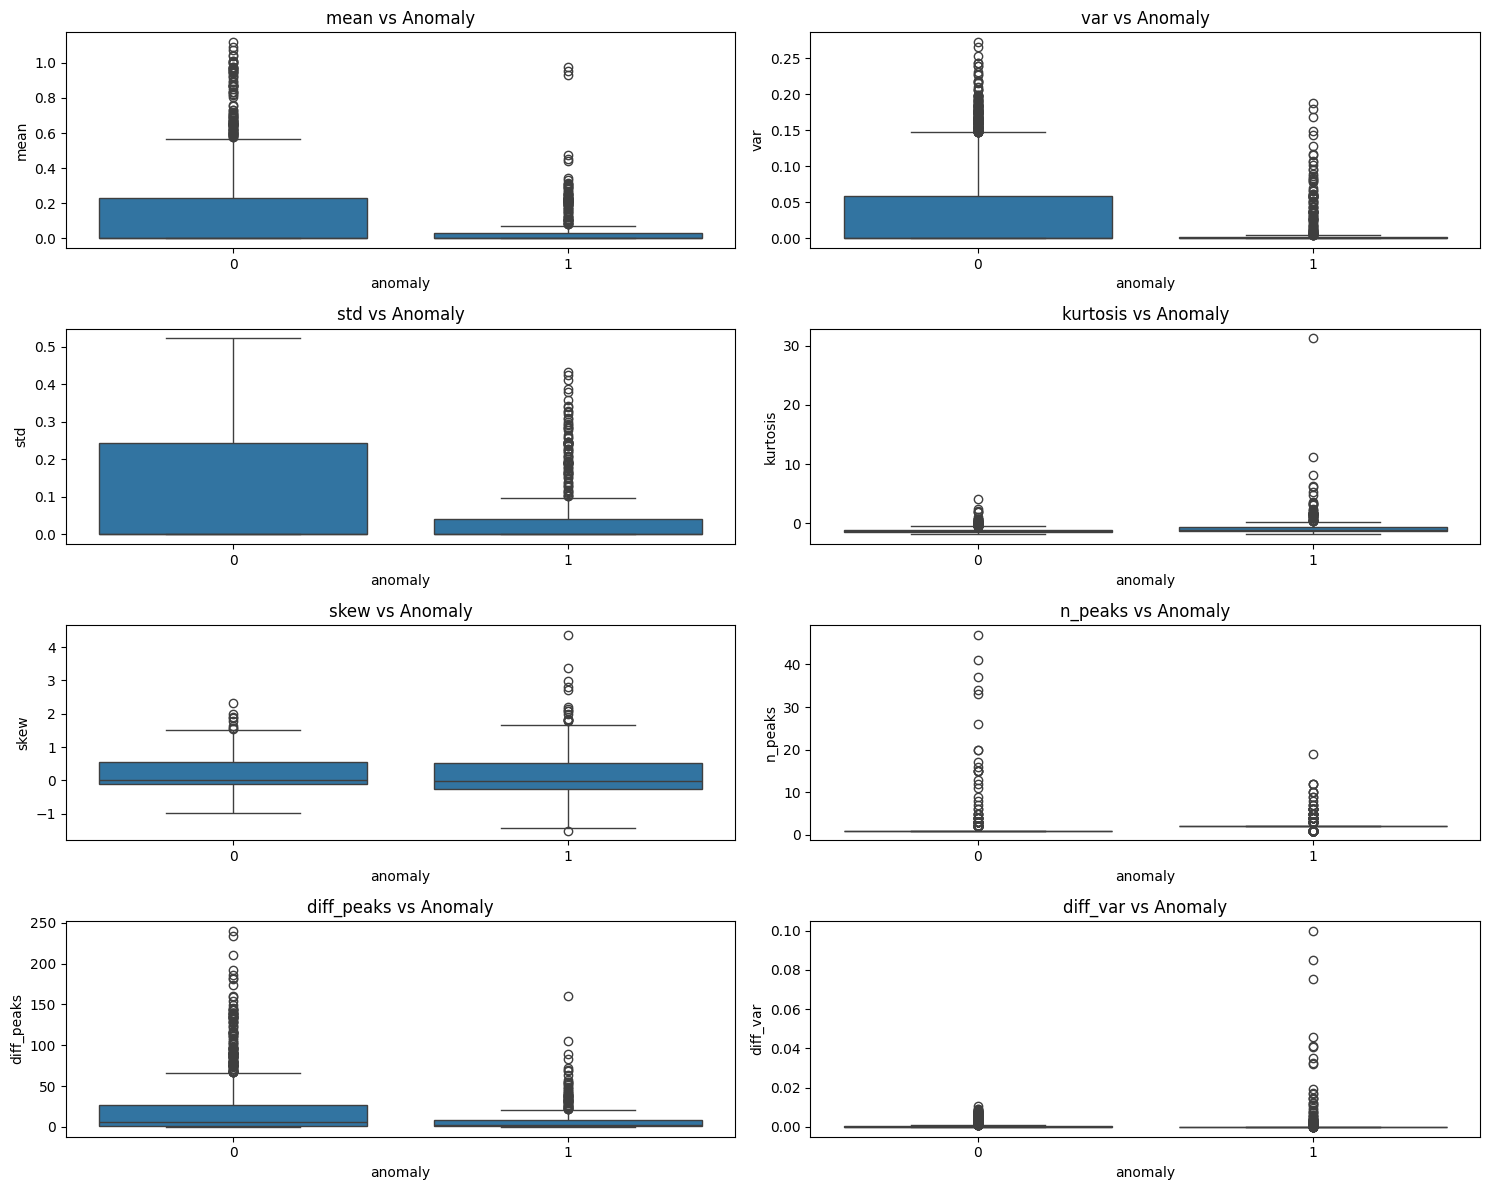

In [142]:
features = ['mean', 'var', 'std', 'kurtosis',
            'skew', 'n_peaks', 'diff_peaks', 'diff_var']

plt.figure(figsize=(15,12))

for i, col in enumerate(features):
    plt.subplot(4,2,i+1)
    sns.boxplot(data=df, x='anomaly', y=col)
    plt.title(f'{col} vs Anomaly')

plt.tight_layout()
plt.show()

In [143]:
df.groupby('anomaly').mean(numeric_only=True).T

anomaly,0,1
segment,1103.593843,900.129032
train,0.753700,0.739631
sampling,3.768502,2.483871
duration,251.026051,322.384793
len,120.325044,231.023041
mean,0.127079,0.048267
var,0.035830,0.010532
std,0.109114,0.046069
kurtosis,-1.204101,-0.623907
skew,0.178396,0.164479


In [144]:
x = df.drop(columns=['anomaly','segment','train'])
y = df['anomaly']

```markdown
## Step 4: Dataset Splitting
Separating the features into train and test groups using the designated `train` division flag.
```

In [145]:
pd.crosstab(df['train'], df['anomaly'])

anomaly,0,1
train,,
0,416,113
1,1273,321


In [146]:
train_mask = df['train'] == 1
test_mask = df['train'] == 0

In [147]:
x_train  =x[train_mask]
x_test  = x[test_mask]

y_train  =y[train_mask]
y_test = y[test_mask]

In [148]:
print("x_train:", x_train.shape)
print("x_test:", x_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

x_train: (1594, 20)
x_test: (529, 20)
y_train: (1594,)
y_test: (529,)


```markdown
## Step 5: Data Preprocessing
Applying One-Hot Encoding on categorical attributes and Standard Scaling on numerical attributes.
```

In [149]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

x_train_encoded = encoder.fit_transform(x_train[cat_cols])
x_test_encoded = encoder.transform(x_test[cat_cols])

In [150]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train[num_cols])
x_test_scaled = scaler.transform(x_test[num_cols])

In [151]:


X_train_final = np.concatenate([x_train_scaled, x_train_encoded], axis=1)

X_test_final = np.concatenate([x_test_scaled, x_test_encoded], axis=1)

```markdown
## Step 6: Predictive Modeling and Evaluation
### Model 1: Logistic Regression Classifier
```

In [152]:
from sklearn.linear_model import LogisticRegression
lc = LogisticRegression()
lc.fit(X_train_final,y_train)
y_pred=lc.predict(X_test_final)

In [153]:
print("Actual values:")
print(y_test.values[:10])

print("Predicted values:")
print(y_pred[:10])

Actual values:
[0 0 0 1 0 1 1 0 0 1]
Predicted values:
[0 0 0 1 0 1 1 0 0 1]


In [154]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
print("Accuracy:",(accuracy_score(y_test,y_pred)))
print(classification_report(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))

Accuracy: 0.9527410207939508
              precision    recall  f1-score   support

           0       0.95      0.99      0.97       416
           1       0.97      0.81      0.88       113

    accuracy                           0.95       529
   macro avg       0.96      0.90      0.92       529
weighted avg       0.95      0.95      0.95       529

[[413   3]
 [ 22  91]]


```markdown
### Model 2: Random Forest Classifier
```

In [155]:
from sklearn.ensemble import RandomForestClassifier
rfc = RandomForestClassifier(n_estimators=100,random_state=42)
rfc.fit(X_train_final,y_train)
y_pred=rfc.predict(X_test_final)

In [156]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
print("Accuracy:",(accuracy_score(y_test,y_pred)))
print(classification_report(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))


Accuracy: 0.9640831758034026
              precision    recall  f1-score   support

           0       0.96      0.99      0.98       416
           1       0.96      0.87      0.91       113

    accuracy                           0.96       529
   macro avg       0.96      0.93      0.94       529
weighted avg       0.96      0.96      0.96       529

[[412   4]
 [ 15  98]]


```markdown
### Model 3: Decision Tree Classifier
```

In [157]:
from sklearn.tree import DecisionTreeClassifier
dtc = DecisionTreeClassifier(random_state=42)
dtc.fit(X_train_final,y_train)
y_pred=dtc.predict(X_test_final)

In [158]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
print("Accuracy:",(accuracy_score(y_test,y_pred)))
print(classification_report(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))

Accuracy: 0.943289224952741
              precision    recall  f1-score   support

           0       0.96      0.97      0.96       416
           1       0.89      0.84      0.86       113

    accuracy                           0.94       529
   macro avg       0.92      0.91      0.91       529
weighted avg       0.94      0.94      0.94       529

[[404  12]
 [ 18  95]]


```markdown
## Step 7: Model Comparison & Synthesis
```

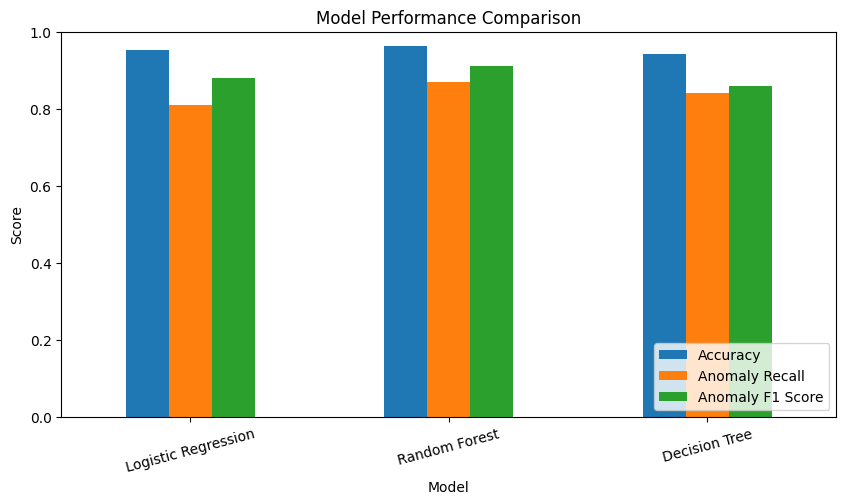

In [159]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'Decision Tree'
    ],
    'Accuracy': [
        0.9527,
        0.9641,
        0.9433
    ],
    'Anomaly Recall': [
        0.81,
        0.87,
        0.84
    ],
    'Anomaly F1 Score': [
        0.88,
        0.91,
        0.86
    ]
})

results.set_index('Model').plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.show()

After comparing the 3 models we understand that random forest is the best amoung them s now predicting using random forest

```markdown
## Step 8: Production Inference Engine
Deploying the champion Random Forest model to flag anomalies on real-time sample payloads.
```

In [160]:
y_pred1 = rfc.predict(np.concatenate([scaler.transform([[1, 198, 199, 3.98613059798995e-06, 1.4249355135748187e-10, 1.1937066279345267e-05, -1.09267254842308, 0.3714784956999048, 1, 1, 1, 19, 16, 3.387310865985416e-12, 7.259268003026522e-12, 198, 199, 7.19664400795363e-13, 7.160479967712657e-13]]), encoder.transform([['CADC0872']])], axis=1))
y_pred1
if y_pred1 >= 1:
  print('Anomaly')
else:
  print('Normal')

Anomaly


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but OneHotEncoder was fitted with feature names
  warnings.warn(


In [161]:
y_pred_new1 = rfc.predict(np.concatenate([scaler.transform([[1, 350, 351, 2.5e-06, 4.8e-10, 2.19e-05, -0.4, 0.3, 5, 4, 2, 6, 9, 3.0e-12, 8.0e-12, 350, 351, 1.4e-12, 1.37e-12]]), encoder.transform([['CADC0873']])], axis=1))
y_pred_new1
if y_pred_new1 >= 1:
  print('Anomaly')
else:
  print('Normal')

Anomaly


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but OneHotEncoder was fitted with feature names
  warnings.warn(


In [162]:
y_pred3 = rfc.predict(np.concatenate([scaler.transform([[1, 213, 214, -1.104237738317757e-06, 2.435482513359998e-10, 1.5606032530274945e-05, -1.0863347541610358, -0.3215406848946128, 1, 1, 1, 47, 51, 1.5541308586841698e-12, 3.651738322983825e-12, 213, 214, 1.1434190203568064e-12, 1.138075940822429e-12]]), encoder.transform([['CADC0872']])], axis=1))
y_pred3
if y_pred3 >= 1:
  print('Anomaly')
else:
  print('Normal')

Normal


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but OneHotEncoder was fitted with feature names
  warnings.warn(
